# Pulse demo

Minimal sanity check: build a single DRAG-corrected Gaussian pulse and plot the real (Ω_x) and imaginary (Ω_y) components.

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import numpy as np
import matplotlib.pyplot as plt
import drape_lib as dl

%matplotlib inline

## Pulse specs

In [2]:
amp_uncorrected = 0.2512        # rough Rabi calibrated, from Rabi on |1>↔|2>
tg              = dl.DEFAULT_TG
sigma           = tg / 4        # == dl.DEFAULT_SIGMA
beta_demo       = 0.1           # normalized units

## Build a single-pulse train and sample the waveform

In [3]:
pulse_train = {'clock': 0}
dl.add_pulse(pulse_train, 'Gaussian',
             start=pulse_train['clock'], tg=tg, sigma=sigma,
             A=amp_uncorrected, beta=beta_demo)

times             = np.linspace(0, 2*tg, 100)
waveform_Gaussian = np.array([dl.Omega_x(t, pulse_train) for t in times])
waveform_DRAG     = np.array([dl.Omega_y(t, pulse_train) for t in times])
waveform_complex  = np.array([dl.Omega(t,   pulse_train) for t in times])

## Plot

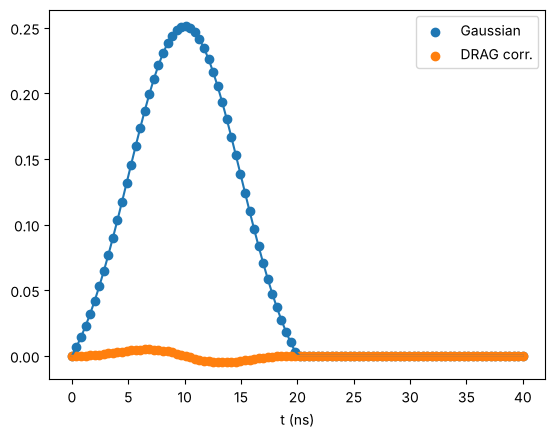

In [4]:
fig, ax = plt.subplots()
ax.scatter(times, waveform_Gaussian, label='Gaussian')
ax.plot(times,  np.real(waveform_complex))
ax.scatter(times, waveform_DRAG,    label='DRAG corr.')
ax.plot(times, -np.imag(waveform_complex))
ax.set_xlabel('t (ns)')
ax.legend()